<a href="https://colab.research.google.com/github/AyoubElKharraf/NeRF_LRM__From_2D_to_3D/blob/main/LRM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install objaverse

import objaverse, random

# Objets classés par catégorie (annotations LVIS)
lvis = objaverse.load_lvis_annotations()
print(list(lvis.keys())[:50])   # pour voir les catégories dispo

categorie = "chair"             # à remplacer par ton domaine
uids = lvis[categorie]
print(len(uids), "objets disponibles")

# Filtre de licence (important si le projet est commercial)
annotations = objaverse.load_annotations(uids)
ok = [u for u in uids if annotations[u]["license"] in ("by", "cc0", "by-sa")]
random.seed(0)
ok = random.sample(ok, min(1000, len(ok)))

# Téléchargement des fichiers .glb
objets = objaverse.load_objects(uids=ok, download_processes=4)
# objets = {uid: "chemin/vers/objet.glb"}

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for gputil: filename=gputil-1.4.0-py3-none-any.whl size=7434 sha256=11ffe0a760b7d147fb071d2e020a142bf1ac00e6d64d8ec38e8aad7fc2092bbb
  Stored in directory: /root/.cache/pip/wheels/ec/ae/c6/43c88094e51d00abb1f20a8acd65dc7af7dce93057c46f2eff
Successfully built gputil
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [objaverse]
['Band_Aid', 'Bible', 'CD_player', 'Christmas_tree', 'Dixie_cup', 'Ferris_wheel', 'Lego', 'Rollerblade', 'Sharpie', 'Tabasco_sauce', 'aerosol_can', 'air_conditioner', 'airplane', 'alarm_clock', 'alcohol', 'alligator', 'almond', 'ambulance', 'amplifier', 'anklet', 'antenna', 'apple', 'apricot', 'apron', 'aquarium', 'arctic_(type_of_shoe)', 'armband', 'armchair', 'armoire', 'armor', 'army_tank', 'artichoke', 'ashtray', 'asparagus', 'atomizer', 'automatic_washer', 'avocado', 'award', 'awning', 'ax', 'baboon', 'baby_buggy

 99%|█████████▉| 151/152 [01:55<00:00,  1.30it/s]


starting download of 449 objects with 4 processes
Downloaded 1 / 449 objects
DownloadedDownloaded  2 /3  449/objects  
449 objects
Downloaded 4 / 449 objects
Downloaded 5 / 449 objects
Downloaded 6 / 449 objects
Downloaded 7 / 449 objects
Downloaded 8 / 449 objects
Downloaded 9 / 449 objects
Downloaded Downloaded11 / 449  objects
11 / 449 objects
Downloaded 12 / 449 objects
Downloaded 13 / 449 objects
Downloaded 14 / 449 objects
Downloaded 15 / 449 objects
Downloaded 16 / 449 objects
Downloaded 17 / 449 objects
Downloaded 18 / 449 objects
Downloaded 19 /Downloaded  20449 /  objects449
 objects
Downloaded 21 / 449 objects
Downloaded 22 / 449 objects
Downloaded 23 / 449 objects
Downloaded 24 Downloaded/  25449 / objects 449
 objects
Downloaded 26 / 449 objects
Downloaded 27 / 449 objects
Downloaded 28 / 449 objects
Downloaded 29 / 449 objects
Downloaded 30 / 449 objects
Downloaded 31 / 449 objects
Downloaded 32 / 449 objects
Downloaded 33 / 449 objects
Downloaded 34 / 449 objects
Downloa

In [ ]:
!wget -q https://download.blender.org/release/Blender3.6/blender-3.6.5-linux-x64.tar.xz
!tar -xf blender-3.6.5-linux-x64.tar.xz
!apt-get -qq install -y libxi6 libxrender1 libxkbcommon0 libsm6

In [ ]:
import os
uid, path = next(iter(objets.items()))
!./blender-3.6.5-linux-x64/blender -b -P render.py -- {path} /content/renders/{uid} 16
!ls /content/renders/{uid}

Blender 3.6.5 (hash cf1e1ed46b7e built 2023-10-18 23:31:25)
Data are loaded, start creating Blender stuff
glTF import finished in 0.06s
Fra:1 Mem:12.50M (Peak 12.50M) | Time:00:00.02 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Synchronizing object | Object_2
Fra:1 Mem:13.28M (Peak 15.69M) | Time:00:00.04 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Initializing
Fra:1 Mem:12.28M (Peak 15.69M) | Time:00:00.04 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Waiting for render to start
Fra:1 Mem:12.29M (Peak 15.69M) | Time:00:00.04 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Loading render kernels (may take a few minutes the first time)
Fra:1 Mem:12.29M (Peak 15.69M) | Time:00:00.04 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Updating Scene
Fra:1 Mem:12.29M (Peak 15.69M) | Time:00:00.04 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Updating Shaders
Fra:1 Mem:12.29M (Peak 15.69M) | Time:00:00.04 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Updating Procedurals
Fra:1 Mem:12.29M (Peak 15.69M) 

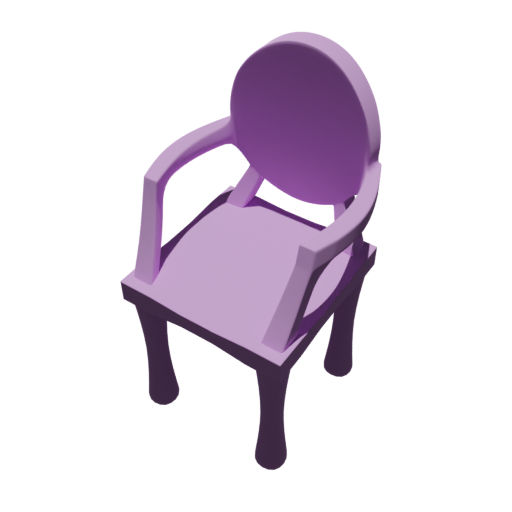

In [ ]:
from PIL import Image
Image.open(f"/content/renders/{uid}/000.png")

In [ ]:
for uid, path in objets.items():
    if os.path.exists(f"/content/renders/{uid}/cameras.json"):
        continue   # reprise possible après déconnexion
    !./blender-3.6.5-linux-x64/blender -b -P render.py -- {path} /content/renders/{uid} 16

Le flux de sortie a été tronqué et ne contient que les 5000 dernières lignes.
Fra:1 Mem:12.28M (Peak 13.09M) | Time:00:00.03 | Mem:2.02M, Peak:2.02M | Scene, ViewLayer | Updating Device | Writing constant memory
Fra:1 Mem:12.28M (Peak 13.09M) | Time:00:00.03 | Mem:2.02M, Peak:2.02M | Scene, ViewLayer | Sample 0/32
Fra:1 Mem:31.29M (Peak 31.29M) | Time:00:00.30 | Remaining:00:08.22 | Mem:21.02M, Peak:21.02M | Scene, ViewLayer | Sample 1/32
Fra:1 Mem:39.29M (Peak 51.29M) | Time:00:11.01 | Mem:21.02M, Peak:21.02M | Scene, ViewLayer | Sample 32/32
Fra:1 Mem:39.29M (Peak 51.29M) | Time:00:11.01 | Mem:21.02M, Peak:21.02M | Scene, ViewLayer | Finished
Saved: '/content/renders/7d7194c2eca748929da17d8ccdbfa6b5/007.png'
 Time: 00:11.06 (Saving: 00:00.05)

Fra:1 Mem:10.98M (Peak 11.54M) | Time:00:00.00 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Synchronizing object | Object_2
Fra:1 Mem:11.37M (Peak 13.09M) | Time:00:00.01 | Mem:0.00M, Peak:0.00M | Scene, ViewLayer | Initializing
Fra:1 Mem:10.73

In [ ]:
!nvidia-smi | head -n 12
!pip install -q objaverse
!wget -q https://download.blender.org/release/Blender3.6/blender-3.6.5-linux-x64.tar.xz
!tar -xf blender-3.6.5-linux-x64.tar.xz
!apt-get -qq install -y libxi6 libxrender1 libxkbcommon0 libsm6

Wed Nov 25 16:19:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import objaverse, random

lvis = objaverse.load_lvis_annotations()
categorie = "chair"   # remplace par ton domaine
uids = lvis[categorie]

annotations = objaverse.load_annotations(uids)
ok = [u for u in uids if annotations[u]["license"] in ("by", "cc0", "by-sa")]
random.seed(0)
ok = random.sample(ok, min(20, len(ok)))

objets = objaverse.load_objects(uids=ok, download_processes=4)
print(len(objets), "objets téléchargés")

 99%|█████████▉| 151/152 [02:20<00:00,  1.07it/s]


starting download of 20 objects with 4 processes
Downloaded 1 / 20 Downloadedobjects 2
 / 20 objects
Downloaded 3 / 20 objects
Downloaded 4 / 20 objects
Downloaded 5 / 20 objects
Downloaded 6 / 20 objects
Downloaded 7 / 20 objects
Downloaded 8 / 20 objects
Downloaded 9 / 20 objects
Downloaded 10 / 20 objects
Downloaded 11 / 20 objects
Downloaded 12 / 20 objects
Downloaded 13 /Downloaded  1420 objects 
/ 20 objects
Downloaded 15 / 20 objects
Downloaded 16 / 20 objects
Downloaded 17 / 20 objects
Downloaded 18 / 20 objects
Downloaded 19 / 20 objects
Downloaded 20 / 20 objects
20 objets téléchargés


In [ ]:
script = r'''
import bpy, sys, json, math, random, os
from mathutils import Vector

glb, out_dir, n_views = sys.argv[-3], sys.argv[-2], int(sys.argv[-1])
os.makedirs(out_dir, exist_ok=True)

bpy.ops.wm.read_factory_settings(use_empty=True)
bpy.ops.import_scene.gltf(filepath=glb)

# Normaliser l'objet dans un cube
meshes = [o for o in bpy.context.scene.objects if o.type == 'MESH']
mins = Vector((1e9,)*3); maxs = Vector((-1e9,)*3)
for o in meshes:
    for c in o.bound_box:
        w = o.matrix_world @ Vector(c)
        mins = Vector(map(min, mins, w)); maxs = Vector(map(max, maxs, w))
center = (mins + maxs) / 2
scale = 1.0 / max((maxs - mins))
for o in bpy.context.scene.objects:
    if o.parent is None:
        o.location = (o.location - center) * scale
        o.scale = o.scale * scale
bpy.context.view_layer.update()

# Lumière
bpy.ops.object.light_add(type='SUN', location=(2, 2, 4))
bpy.context.object.data.energy = 3.0
world = bpy.data.worlds.new("w"); bpy.context.scene.world = world
world.use_nodes = True
world.node_tree.nodes["Background"].inputs[1].default_value = 1.0

# Caméra
cam_data = bpy.data.cameras.new("cam"); cam_data.angle = math.radians(40)
cam = bpy.data.objects.new("cam", cam_data)
bpy.context.scene.collection.objects.link(cam)
bpy.context.scene.camera = cam

# Rendu rapide sur GPU
sc = bpy.context.scene
sc.render.engine = 'CYCLES'
sc.cycles.samples = 8
prefs = bpy.context.preferences.addons['cycles'].preferences
prefs.compute_device_type = 'CUDA'
prefs.get_devices()
for d in prefs.devices:
    d.use = True
sc.cycles.device = 'GPU'
sc.render.resolution_x = sc.render.resolution_y = 256
sc.render.film_transparent = True
sc.render.image_settings.color_mode = 'RGBA'

frames = []
random.seed(0)
for i in range(n_views):
    az = random.uniform(0, 2 * math.pi)
    el = random.uniform(math.radians(-10), math.radians(60))
    r = 1.8
    cam.location = (r*math.cos(el)*math.cos(az), r*math.cos(el)*math.sin(az), r*math.sin(el))
    d = Vector((0, 0, 0)) - cam.location
    cam.rotation_euler = d.to_track_quat('-Z', 'Y').to_euler()
    bpy.context.view_layer.update()
    sc.render.filepath = os.path.join(out_dir, f"{i:03d}.png")
    bpy.ops.render.render(write_still=True)
    frames.append({"file": f"{i:03d}.png",
                   "c2w": [list(row) for row in cam.matrix_world],
                   "fov_deg": 40})
json.dump(frames, open(os.path.join(out_dir, "cameras.json"), "w"))
'''
open("render.py", "w").write(script)
print("render.py créé")

render.py créé


In [ ]:
import os, time
t = time.time()
for uid, path in list(objets.items())[:5]:
    if os.path.exists(f"/content/renders/{uid}/cameras.json"):
        continue
    !./blender-3.6.5-linux-x64/blender -b -P render.py -- {path} /content/renders/{uid} 8 > /dev/null 2>&1
print("Temps :", round(time.time() - t), "secondes")

Temps : 52 secondes


['006.png', '003.png', '005.png', '001.png', 'cameras.json', '004.png', '007.png', '002.png', '000.png']


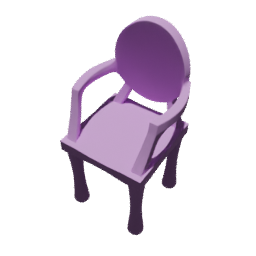

In [ ]:
from PIL import Image
uid = list(objets.keys())[0]
print(os.listdir(f"/content/renders/{uid}"))
Image.open(f"/content/renders/{uid}/000.png")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!cp -r /content/renders /content/drive/MyDrive/renders

Mounted at /content/drive


In [ ]:
im = Image.open(f"/content/renders/{uid}/000.png")
print(im.mode, im.getpixel((0, 0)))

RGBA (0, 0, 0, 0)


In [ ]:
import os, time
t = time.time()
for uid, path in objets.items():
    if os.path.exists(f"/content/renders/{uid}/cameras.json"):
        continue
    !./blender-3.6.5-linux-x64/blender -b -P render.py -- {path} /content/renders/{uid} 8 > /dev/null 2>&1
print("Temps :", round(time.time() - t), "secondes")

!cp -r /content/renders/* /content/drive/MyDrive/renders/

Temps : 152 secondes


In [ ]:
ok = [d for d in os.listdir("/content/renders") if os.path.exists(f"/content/renders/{d}/cameras.json")]
print(len(ok), "objets rendus")

20 objets rendus


In [ ]:
!git clone https://github.com/VAST-AI-Research/TripoSR.git
!pip install -q omegaconf einops transformers trimesh rembg onnxruntime
!ls TripoSR TripoSR/tsr
!cat TripoSR/tsr/system.py | head -n 120

Cloning into 'TripoSR'...
remote: Enumerating objects: 164, done.
remote: Counting objects: 100% (98/98), done.
remote: Compressing objects: 100% (53/53), done.
remote: Total 164 (delta 66), reused 45 (delta 45), pack-reused 66 (from 1)
Receiving objects: 100% (164/164), 36.71 MiB | 38.01 MiB/s, done.
Resolving deltas: 100% (68/68), done.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
TripoSR:
examples  gradio_app.py  README.md	   run.py
figures   LICENSE	 requirements.txt  tsr

TripoSR/tsr:
bake_texture.py  models  system.py  utils.py
import math
import os
from dataclasses import dataclass, field
from typing import List, Union

import numpy as np
import PIL.Image
import torch
import torch.nn.functional as F
import trimesh
from einops import rearrange
from huggingface_h

In [ ]:
!sed -n 120,200p TripoSR/tsr/system.py

        return scene_codes

    def render(
        self,
        scene_codes,
        n_views: int,
        elevation_deg: float = 0.0,
        camera_distance: float = 1.9,
        fovy_deg: float = 40.0,
        height: int = 256,
        width: int = 256,
        return_type: str = "pil",
    ):
        rays_o, rays_d = get_spherical_cameras(
            n_views, elevation_deg, camera_distance, fovy_deg, height, width
        )
        rays_o, rays_d = rays_o.to(scene_codes.device), rays_d.to(scene_codes.device)

        def process_output(image: torch.FloatTensor):
            if return_type == "pt":
                return image
            elif return_type == "np":
                return image.detach().cpu().numpy()
            elif return_type == "pil":
                return Image.fromarray(
                    (image.detach().cpu().numpy() * 255.0).astype(np.uint8)
                )
            else:
                raise NotImplementedError

        images = []
        for sc

In [ ]:
import torch, sys
sys.path.append("/content/TripoSR")
from PIL import Image
from tsr.system import TSR
from tsr.utils import remove_background, resize_foreground, save_video
import rembg

device = "cuda"
model = TSR.from_pretrained(
    "stabilityai/TripoSR",
    config_name="config.yaml",
    weight_name="model.ckpt",
)
model.renderer.set_chunk_size(8192)
model.to(device)

# Image d'entrée (photo ou rendu de chaise)
image = Image.open("/content/test.png")
rgba = image.convert("RGBA")
rembg_session = rembg.new_session()
image = remove_background(image.convert("RGB"), rembg_session)
image = resize_foreground(image, 0.85)
arr = np.array(image).astype("float32") / 255.0 if False else None

ModuleNotFoundError: No module named 'torchmcubes'

In [ ]:
!pip install -q git+https://github.com/tatsy/torchmcubes.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (pyproject.toml) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> from git+https://github.com/tatsy/torchmcubes.git

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


In [ ]:
!pip install -q cmake ninja scikit-build-core pybind11
!pip install -q --no-build-isolation git+https://github.com/tatsy/torchmcubes.git

  Preparing metadata (pyproject.toml) ... done


In [ ]:
import glob, shutil
fichiers = sorted(glob.glob("/content/drive/MyDrive/renders/*/000.png"))
print(len(fichiers), "images trouvées")
shutil.copy(fichiers[0], "/content/test.png")

20 images trouvées


'/content/test.png'

In [ ]:
!pip install -q "transformers<5"

In [ ]:
!ls /content/TripoSR | head -n 3
!ls /content/test.png

examples
figures
gradio_app.py
/content/test.png


In [ ]:
import torch, sys, numpy as np
sys.path.append("/content/TripoSR")
from PIL import Image
from tsr.system import TSR
from tsr.utils import remove_background, resize_foreground, save_video
import rembg

device = "cuda"
model = TSR.from_pretrained(
    "stabilityai/TripoSR",
    config_name="config.yaml",
    weight_name="model.ckpt",
)
model.renderer.set_chunk_size(8192)
model.to(device)

image = Image.open("/content/test.png")
image = remove_background(image.convert("RGB"), rembg.new_session())
image = resize_foreground(image, 0.85)
arr = np.array(image).astype(np.float32) / 255.0
arr = arr[:, :, :3] * arr[:, :, 3:4] + (1 - arr[:, :, 3:4]) * 0.5
image = Image.fromarray((arr * 255).astype(np.uint8))

with torch.no_grad():
    scene_codes = model([image], device=device)

frames = model.render(scene_codes, n_views=30, return_type="pil")
save_video(frames[0], "/content/render.mp4", fps=30)

mesh = model.extract_mesh(scene_codes, True, resolution=256)[0]
mesh.export("/content/mesh.obj")
print("OK")

RuntimeError: Error(s) in loading state_dict for TSR:
	Missing key(s) in state_dict: "image_tokenizer.model.layers.0.attention.q_proj.weight", "image_tokenizer.model.layers.0.attention.q_proj.bias", "image_tokenizer.model.layers.0.attention.k_proj.weight", "image_tokenizer.model.layers.0.attention.k_proj.bias", "image_tokenizer.model.layers.0.attention.v_proj.weight", "image_tokenizer.model.layers.0.attention.v_proj.bias", "image_tokenizer.model.layers.0.attention.o_proj.weight", "image_tokenizer.model.layers.0.attention.o_proj.bias", "image_tokenizer.model.layers.0.layernorm_before.weight", "image_tokenizer.model.layers.0.layernorm_before.bias", "image_tokenizer.model.layers.0.layernorm_after.weight", "image_tokenizer.model.layers.0.layernorm_after.bias", "image_tokenizer.model.layers.0.mlp.fc1.weight", "image_tokenizer.model.layers.0.mlp.fc1.bias", "image_tokenizer.model.layers.0.mlp.fc2.weight", "image_tokenizer.model.layers.0.mlp.fc2.bias", "image_tokenizer.model.layers.1.attention

In [ ]:
import transformers
print(transformers.__version__)

5.22.1


In [ ]:
!pip install "transformers==4.46.3" "tokenizers>=0.20,<0.21"

In [ ]:
import os
os.kill(os.getpid(), 9)

In [ ]:
import transformers
print(transformers.__version__)   # doit afficher 4.46.3

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

4.46.3


In [ ]:
import torch, sys, numpy as np
sys.path.append("/content/TripoSR")
from PIL import Image
from tsr.system import TSR
from tsr.utils import remove_background, resize_foreground, save_video
import rembg

device = "cuda"
model = TSR.from_pretrained(
    "stabilityai/TripoSR",
    config_name="config.yaml",
    weight_name="model.ckpt",
)
model.renderer.set_chunk_size(8192)
model.to(device)

image = Image.open("/content/test.png")
image = remove_background(image.convert("RGB"), rembg.new_session())
image = resize_foreground(image, 0.85)
arr = np.array(image).astype(np.float32) / 255.0
arr = arr[:, :, :3] * arr[:, :, 3:4] + (1 - arr[:, :, 3:4]) * 0.5
image = Image.fromarray((arr * 255).astype(np.uint8))

with torch.no_grad():
    scene_codes = model([image], device=device)

frames = model.render(scene_codes, n_views=30, return_type="pil")
save_video(frames[0], "/content/render.mp4", fps=30)

mesh = model.extract_mesh(scene_codes, True, resolution=256)[0]
mesh.export("/content/mesh.obj")
print("OK")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


  0%|                                              | 0.00/1.02G [00:00<?, ?B/s]

/content/TripoSR/tsr/utils.py:376: UserWarning: Using torch.cross without specifying the dim arg is deprecated.
Please either pass the dim explicitly or simply use torch.linalg.cross.
The default value of dim will change to agree with that of linalg.cross in a future release. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/Cross.cpp:63.)
  right = F.normalize(torch.cross(lookat, up), dim=-1)


OK


In [ ]:
from IPython.display import Video
Video("/content/render.mp4", embed=True, width=400)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
